# 03 — Recording checks and same-recording evaluation

**Purpose.** The core result. Show that the recordings are separable before any attack occurs,
and that moving the background from a separate recording to the same recording reverses the
apparent modality ranking.

**Inputs**  `results/paper_tables/window_sensitivity_summary.csv`, `session_probe_results.csv`,
`operating_support_summary.csv`.

**Outputs**  `results/regenerated/recording_checks_summary.csv`.


In [1]:
import os, sys
from pathlib import Path
if 'google.colab' in sys.modules:
    from google.colab import drive; drive.mount('/content/drive')
    os.environ.setdefault('PROVICS_ROOT', '/content/drive/MyDrive/provics-recording-aware-evaluation')
else:
    os.environ.setdefault('PROVICS_ROOT', str(Path.cwd().parent))
sys.path.insert(0, os.environ['PROVICS_ROOT'])
from src.utils.paths import project_root
ROOT = project_root(); print('Project folder:', ROOT.name)

# Render compact, readable tables below each cell.
from IPython.display import display
import pandas as pd
pd.set_option('display.max_rows', 30)
pd.set_option('display.max_columns', 12)
pd.set_option('display.precision', 4)


Project folder: code


In [2]:
import pandas as pd
summary = pd.read_csv(ROOT / 'results/paper_tables/window_sensitivity_summary.csv')
print('rows:', len(summary), '= 4 windows x 4 views x 5 seeds')
print('seeds:', sorted(summary.seed.unique()))
print()
print('Seeds are repeated fits nested within a forward step. They are NOT independent samples,',
      'so they are aggregated by median/mean and never counted as replications.')


rows: 80 = 4 windows x 4 views x 5 seeds
seeds: [42, 43, 44, 45, 46]

Seeds are repeated fits nested within a forward step. They are NOT independent samples, so they are aggregated by median/mean and never counted as replications.


In [3]:
# Pre-attack recording check: windows before the first labeled action, so no attack activity
# is present. Strong separability here is a property of the recordings, not of the attack.
cells = summary.groupby(['window_s','modality']).agg(
    pre_attack_auc=('pre_auc','mean'), cross=('cross_auc','mean'),
    within=('within_auc','mean'), delta_cw=('delta_cw','mean')).reset_index()
cyber = cells[cells.modality != 'M4']
print('pre-attack AUC, cyber views M1-M3: %.3f - %.3f' % (cyber.pre_attack_auc.min(), cyber.pre_attack_auc.max()))
print('pre-attack AUC, physical view M4 : %.3f - %.3f' % (
      cells[cells.modality=='M4'].pre_attack_auc.min(), cells[cells.modality=='M4'].pre_attack_auc.max()))
display(cells[['window_s', 'modality', 'pre_attack_auc', 'cross', 'within', 'delta_cw']].round(3))


pre-attack AUC, cyber views M1-M3: 0.944 - 0.998
pre-attack AUC, physical view M4 : 0.763 - 0.786


,window_s,modality,pre_attack_auc,cross,within,delta_cw
0,5,M1,0.944,0.947,0.510,0.437
1,5,M2,0.988,0.986,0.451,0.535
2,5,M3,0.996,1.000,0.537,0.463
3,5,M4,0.781,0.951,0.775,0.176
4,10,M1,0.970,0.971,0.518,0.453
5,10,M2,0.993,0.992,0.463,0.529
6,10,M3,0.996,1.000,0.539,0.461
7,10,M4,0.786,0.951,0.782,0.169
8,30,M1,0.985,0.988,0.553,0.435
9,30,M2,0.985,0.980,0.520,0.460


In [4]:
# The ranking reversal, shown side by side at each window size.
for window in (5, 10, 30, 60):
    block = cells[cells.window_s == window]
    by_cross  = ' > '.join(block.sort_values('cross',  ascending=False).modality)
    by_within = ' > '.join(block.sort_values('within', ascending=False).modality)
    print(f'{window:>3} s   cross-recording: {by_cross:<22} same-recording: {by_within}')
print()
print('The four window sizes are correlated re-aggregations of one recording pair.',
      'Consistency across them is a sensitivity result, not four independent confirmations.')


  5 s   cross-recording: M3 > M2 > M4 > M1      same-recording: M4 > M3 > M1 > M2
 10 s   cross-recording: M3 > M2 > M1 > M4      same-recording: M4 > M3 > M1 > M2
 30 s   cross-recording: M3 > M1 > M2 > M4      same-recording: M4 > M3 > M1 > M2
 60 s   cross-recording: M3 > M1 > M2 > M4      same-recording: M4 > M1 > M3 > M2

The four window sizes are correlated re-aggregations of one recording pair. Consistency across them is a sensitivity result, not four independent confirmations.


In [5]:
# Delta_CW: how much apparent performance depends on the background coming from elsewhere.
pivot = cells.pivot(index='modality', columns='window_s', values='delta_cw').round(3)
display(pivot)
print('\nrange %.3f - %.3f; positive in every cell' % (cells.delta_cw.min(), cells.delta_cw.max()))
print('M4 has the smallest gap at every window size.')


window_s,5,10,30,60
modality,,,,
M1,0.437,0.453,0.435,0.404
M2,0.535,0.529,0.460,0.396
M3,0.463,0.461,0.441,0.418
M4,0.176,0.169,0.149,0.159



range 0.149 - 0.535; positive in every cell
M4 has the smallest gap at every window size.


### Compare the same modalities under two backgrounds

Each panel uses the existing five-seed mean for one window size. Only the negative population differs between the two bars. These panels reuse the same recordings and are not independent replications.


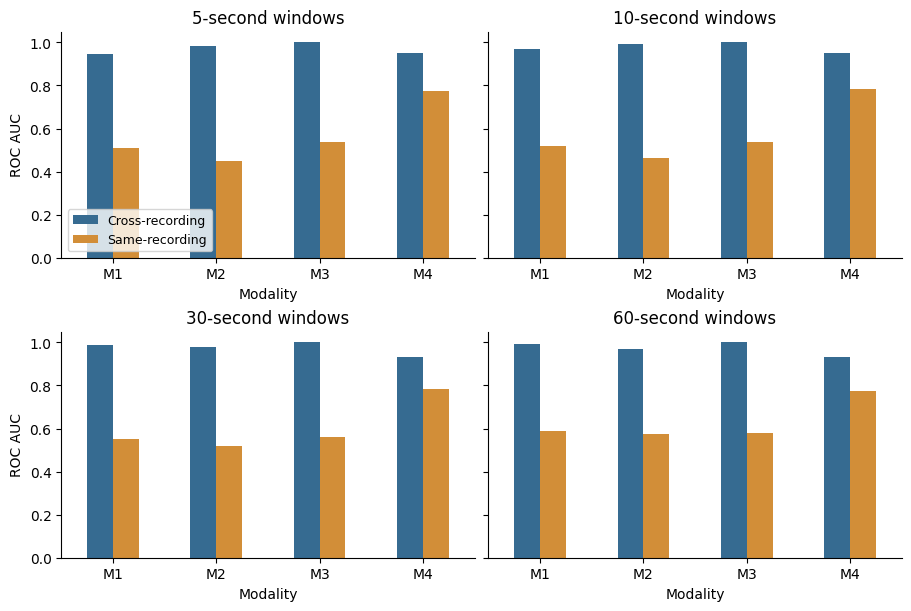

In [6]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 2, figsize=(9, 6), sharey=True, layout='constrained')
for ax, window in zip(axes.flat, (5, 10, 30, 60)):
    block = cells[cells.window_s == window].set_index('modality').loc[['M1', 'M2', 'M3', 'M4']]
    block[['cross', 'within']].rename(columns={'cross': 'Cross-recording', 'within': 'Same-recording'}).plot.bar(
        ax=ax, color=['#366b91', '#d28e38'], rot=0, legend=False)
    ax.set(title=f'{window}-second windows', xlabel='Modality', ylabel='ROC AUC', ylim=(0, 1.05))
    ax.spines[['top', 'right']].set_visible(False)
axes[0, 0].legend(loc='lower left', fontsize=9)
plt.show()
plt.close(fig)

In [7]:
# A separate probe predicts which recording a window came from, using no attack labels.
probe = pd.read_csv(ROOT / 'results/paper_tables/session_probe_results.csv')
table = probe.groupby(['window_s','modality','model']).auc.mean().unstack().round(3)
display(table)
print('\nThis is recording-membership separability on two recordings, not session identification.')


model              logistic_regression    mlp  random_forest
window_s modality                                           
5        M1                      1.000  0.999          1.000
         M2                      1.000  1.000          1.000
         M3                      1.000  1.000          1.000
         M4                      0.677  0.875          0.878
10       M1                      1.000  0.998          1.000
         M2                      1.000  1.000          1.000
         M3                      1.000  1.000          1.000
         M4                      0.752  0.905          0.891
30       M1                      1.000  0.996          1.000
         M2                      1.000  1.000          1.000
         M3                      1.000  1.000          1.000
         M4                      0.812  0.926          0.903
60       M1                      1.000  0.991          1.000
         M2                      1.000  1.000          1.000
         M3                      1.000  0.995          1.000
         M4                      0.930  0.963          0.904


This is recording-membership separability on two recordings, not session identification.


In [8]:
# Could operating state explain it? The matching attempt did not reach its balance criterion.
support = pd.read_csv(ROOT / 'results/paper_tables/operating_support_summary.csv')
display(support[['window_s','propensity_separation_auc','max_abs_smd_post','ALL_GATES_PASS']].round(3))
print('\nBalance threshold is 0.10. Post-match maximum |SMD| stays at %.2f-%.2f, so the matched'
      % (support.max_abs_smd_post.min(), support.max_abs_smd_post.max()),
      'comparison was not run and operating regime remains a live alternative explanation.')

out = ROOT / 'results/regenerated'; out.mkdir(parents=True, exist_ok=True)
cells.to_csv(out / 'recording_checks_summary.csv', index=False)
print('\nwrote results/regenerated/recording_checks_summary.csv')


,window_s,propensity_separation_auc,max_abs_smd_post,ALL_GATES_PASS
0,5,0.834,0.246,False
1,10,0.845,0.253,False
2,30,0.863,0.273,False
3,60,0.875,0.474,False



Balance threshold is 0.10. Post-match maximum |SMD| stays at 0.25-0.47, so the matched comparison was not run and operating regime remains a live alternative explanation.

wrote results/regenerated/recording_checks_summary.csv


## What this notebook established

- The cyber views separate the two recordings before the first labeled attack (AUC 0.944-0.998).
- Delta_CW is positive in all 16 cells (0.149-0.535) and the ranking reverses at every window size.
- The physical view M4 is weakest cross-recording but strongest within-recording.
- Operating state could not be balanced, so the source of the difference stays unresolved.
